## Imports and NLTK downloads

In [1]:
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

True

## Step 1: Load the dataset

In [2]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
print("Columns:", train_df.columns.tolist())

class_names = ["World", "Sports", "Business", "Sci/Tech"]

def prepare(d):
    d = d.copy()
    if "Class Index" in d.columns:                    
        d["label_id"] = d["Class Index"].astype(int) - 1
        d["text"] = d["Title"].fillna("") + ". " + d["Description"].fillna("")
    else:                                               # version with text / label
        if d["label"].dtype == object:                  # labels written as names
            d["label_id"] = d["label"].map({n: i for i, n in enumerate(class_names)})
        else:
            d["label_id"] = d["label"].astype(int)
            if d["label_id"].min() == 1:              
                d["label_id"] = d["label_id"] - 1
        d["text"] = d["text"].fillna("")
    d["category"] = d["label_id"].map(lambda i: class_names[i])
    return d

train_df = prepare(train_df)
test_df = prepare(test_df)

print("Train:", train_df.shape, "| Test:", test_df.shape)
print(train_df["category"].value_counts())
train_df[["category", "text"]].head()

Columns: ['text', 'label']
Train: (120000, 4) | Test: (7600, 4)
category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


,category,text
0,Business,Wall St. Bears Claw Back Into the Black (Reute...
1,Business,Carlyle Looks Toward Commercial Aerospace (Reu...
2,Business,Oil and Economy Cloud Stocks' Outlook (Reuters...
3,Business,Iraq Halts Oil Exports from Main Southern Pipe...
4,Business,"Oil prices soar to all-time record, posing new..."


## Step 2: Text preprocessing

In [3]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = html.unescape(text).lower()               # &lt; -> <  and lowercase
    text = re.sub(r"<.*?>", " ", text)               # remove HTML tags
    text = re.sub(r"[^a-z\s]", " ", text)            # keep only letters
    tokens = word_tokenize(text)                     # tokenization
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2]   # stopwords + very short words
    tokens = [lemmatizer.lemmatize(w) for w in tokens]                   # lemmatization
    return " ".join(tokens)

sample = "Oil prices rose 5% on Monday as the markets were watching &lt;b&gt;OPEC&lt;/b&gt; meetings."
print("Original :", sample)
print("Tokens   :", word_tokenize(re.sub(r"[^a-z\s]", " ", re.sub(r"<.*?>", " ", html.unescape(sample).lower()))))
print("Final    :", preprocess(sample))

Original : Oil prices rose 5% on Monday as the markets were watching &lt;b&gt;OPEC&lt;/b&gt; meetings.
Tokens   : ['oil', 'prices', 'rose', 'on', 'monday', 'as', 'the', 'markets', 'were', 'watching', 'opec', 'meetings']
Final    : oil price rose monday market watching opec meeting


In [4]:
train_df["clean_text"] = train_df["text"].apply(preprocess)
test_df["clean_text"] = test_df["text"].apply(preprocess)

print("BEFORE:", train_df["text"][0][:150])
print("AFTER :", train_df["clean_text"][0][:150])

BEFORE: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
AFTER : wall bear claw back black reuters reuters short seller wall street dwindling band ultra cynic seeing green


## Step 3: Feature engineering with TF-IDF

In [5]:
le_classes = class_names
y_train = train_df["label_id"].values    
y_test = test_df["label_id"].values

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(train_df["clean_text"])  
X_test_vec = tfidf.transform(test_df["clean_text"])        

print("TF-IDF shape (train):", X_train_vec.shape)
print("TF-IDF shape (test) :", X_test_vec.shape)

TF-IDF shape (train): (120000, 20000)
TF-IDF shape (test) : (7600, 20000)


## Step 4: Train multiclass classifiers

In [6]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_vec, y_train)
lr_pred = lr.predict(X_test_vec)
lr_acc = accuracy_score(y_test, lr_pred)
print("Logistic Regression accuracy:", round(lr_acc, 4))

Logistic Regression accuracy: 0.9129


In [7]:
svm = LinearSVC()
svm.fit(X_train_vec, y_train)
svm_pred = svm.predict(X_test_vec)
svm_acc = accuracy_score(y_test, svm_pred)
print("Linear SVM accuracy:", round(svm_acc, 4))

Linear SVM accuracy: 0.9179


In [8]:
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)
nb_pred = nb.predict(X_test_vec)
nb_acc = accuracy_score(y_test, nb_pred)
print("Naive Bayes accuracy:", round(nb_acc, 4))

Naive Bayes accuracy: 0.8992


## Step 5: Evaluate the best classical model

In [9]:
results = {"Logistic Regression": lr_acc, "Linear SVM": svm_acc, "Naive Bayes": nb_acc}
best_name = max(results, key=results.get)
best_pred = {"Logistic Regression": lr_pred, "Linear SVM": svm_pred, "Naive Bayes": nb_pred}[best_name]

print("Best classical model:", best_name, "->", round(results[best_name], 4))
print()
print(classification_report(y_test, best_pred, target_names=le_classes))

Best classical model: Linear SVM -> 0.9179

              precision    recall  f1-score   support

       World       0.93      0.91      0.92      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.88      0.88      0.88      1900
    Sci/Tech       0.89      0.90      0.90      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



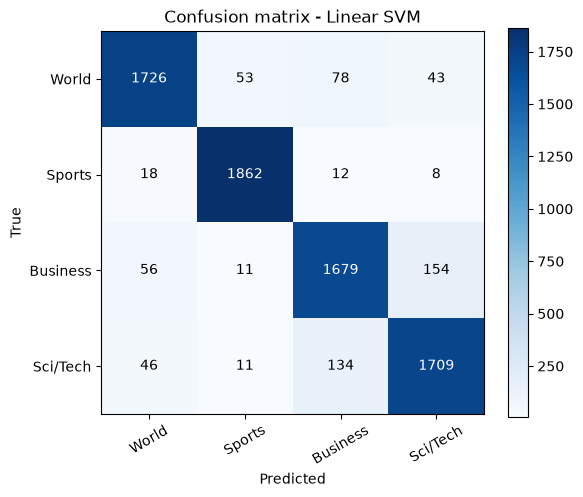

In [10]:
cm = confusion_matrix(y_test, best_pred)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(le_classes, rotation=30)
ax.set_yticks(range(4)); ax.set_yticklabels(le_classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion matrix - {best_name}")
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")   
plt.show()

In [11]:
def predict_category(text, model=svm):
    vec = tfidf.transform([preprocess(text)])
    return le_classes[model.predict(vec)[0]]

tests = [
    "Manchester United beat Chelsea 2-1 in the Premier League final match",
    "Apple unveils a new smartphone with a faster chip and better camera",
    "Stocks fall as oil prices rise and investors worry about inflation",
    "The president meets European leaders to discuss the peace talks",
]
for t in tests:
    print(predict_category(t), "<-", t)

Sports <- Manchester United beat Chelsea 2-1 in the Premier League final match
Sci/Tech <- Apple unveils a new smartphone with a faster chip and better camera
Business <- Stocks fall as oil prices rise and investors worry about inflation
World <- The president meets European leaders to discuss the peace talks


## Step 6 (Bonus): Most frequent words per category

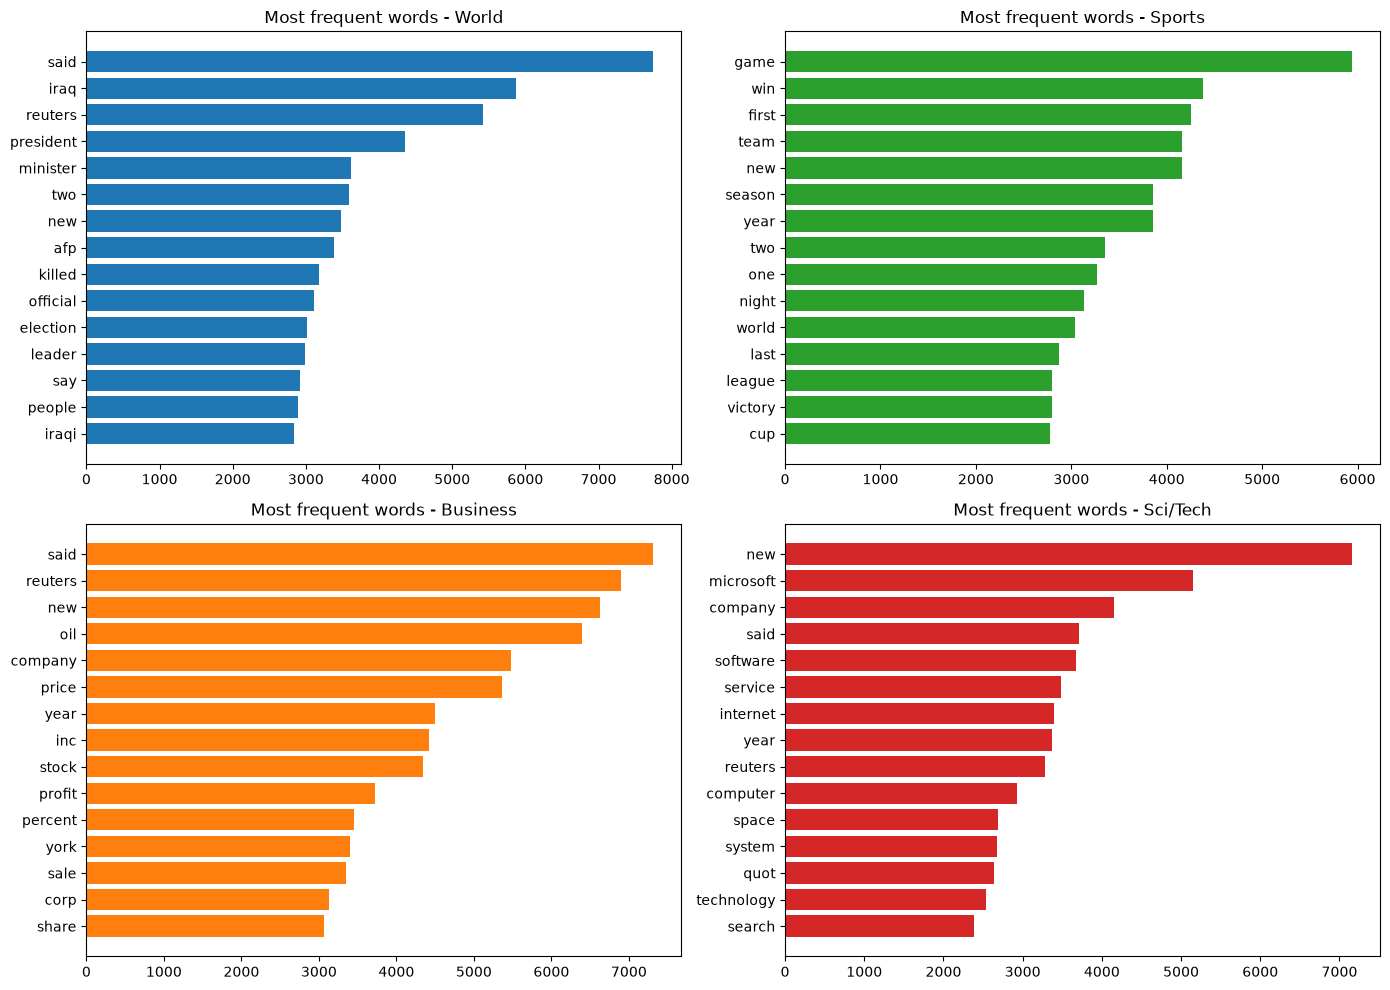

In [12]:
colors = {"World": "tab:blue", "Sports": "tab:green", "Business": "tab:orange", "Sci/Tech": "tab:red"}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, cat in zip(axes.ravel(), le_classes):
    words = " ".join(train_df[train_df["category"] == cat]["clean_text"]).split()
    labels, counts = zip(*Counter(words).most_common(15))
    ax.barh(labels[::-1], counts[::-1], color=colors[cat])
    ax.set_title(f"Most frequent words - {cat}")
plt.tight_layout()
plt.savefig("frequent_words_per_category.png", dpi=150, bbox_inches="tight")
plt.show()

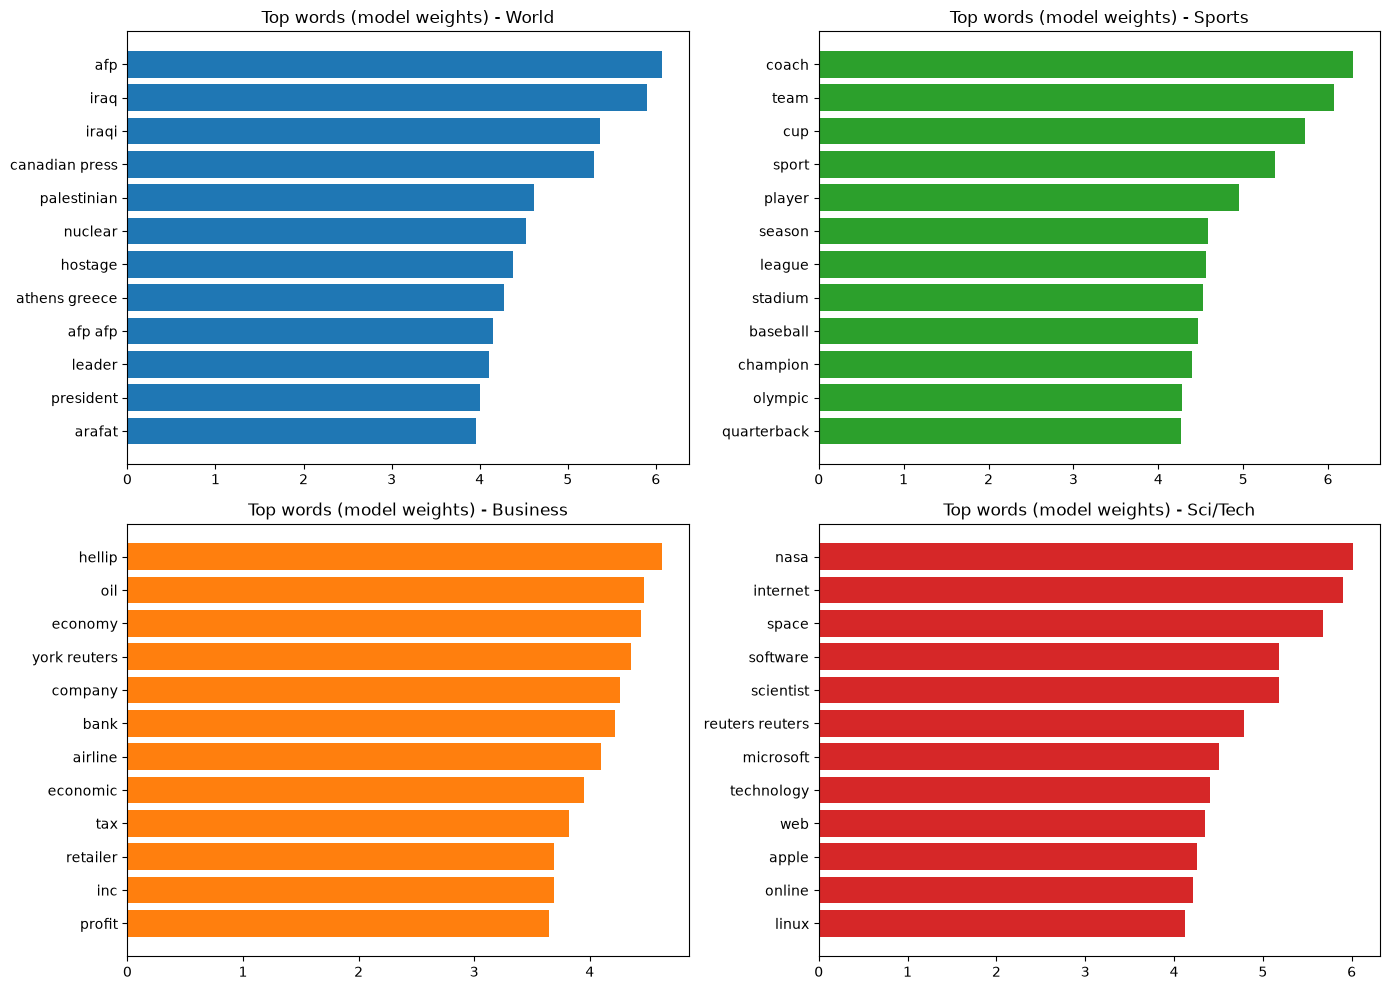

In [13]:
feature_names = np.array(tfidf.get_feature_names_out())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for k, (ax, cat) in enumerate(zip(axes.ravel(), le_classes)):
    coefs = lr.coef_[k]
    top_idx = coefs.argsort()[-12:]
    ax.barh(feature_names[top_idx], coefs[top_idx], color=colors[cat])
    ax.set_title(f"Top words (model weights) - {cat}")
plt.tight_layout()
plt.savefig("top_words_per_category.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 7 (Bonus): Feedforward neural network with Keras

In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

# keep 10% of the training data for validation during training
idx_tr, idx_val = train_test_split(np.arange(X_train_vec.shape[0]), test_size=0.1,
                                   random_state=42, stratify=y_train)

def batch_generator(X, y, indices, batch_size=256, shuffle=True):
    while True:
        order = np.random.permutation(indices) if shuffle else indices
        for start in range(0, len(order), batch_size):
            b = order[start:start + batch_size]
            yield X[b].toarray().astype("float32"), y[b]

BATCH = 256
steps_train = int(np.ceil(len(idx_tr) / BATCH))
steps_val = int(np.ceil(len(idx_val) / BATCH))

model_nn = keras.Sequential([
    layers.Input(shape=(X_train_vec.shape[1],)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(4, activation="softmax"),
])
model_nn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_nn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     5,120,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,121,284 (19.54 MB)

 Trainable params: 5,121,284 (19.54 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model_nn.fit(
    batch_generator(X_train_vec, y_train, idx_tr, BATCH, shuffle=True),
    steps_per_epoch=steps_train,
    validation_data=batch_generator(X_train_vec, y_train, idx_val, BATCH, shuffle=False),
    validation_steps=steps_val,
    epochs=5,
    verbose=1,
)

Epoch 1/5


c:\Users\user\Desktop\elevvo-nlp\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


422/422 ━━━━━━━━━━━━━━━━━━━━ 71s 165ms/step - accuracy: 0.8932 - loss: 0.4217 - val_accuracy: 0.9220 - val_loss: 0.2447
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 69s 163ms/step - accuracy: 0.9300 - loss: 0.2096 - val_accuracy: 0.9228 - val_loss: 0.2351
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 63s 149ms/step - accuracy: 0.9437 - loss: 0.1647 - val_accuracy: 0.9217 - val_loss: 0.2390
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 60s 142ms/step - accuracy: 0.9536 - loss: 0.1332 - val_accuracy: 0.9200 - val_loss: 0.2521
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 59s 140ms/step - accuracy: 0.9621 - loss: 0.1090 - val_accuracy: 0.9173 - val_loss: 0.2690


In [16]:
nn_probs = np.vstack([
    model_nn.predict(X_test_vec[i:i + 1000].toarray().astype("float32"), verbose=0)
    for i in range(0, X_test_vec.shape[0], 1000)
])
nn_pred = nn_probs.argmax(axis=1)
nn_acc = accuracy_score(y_test, nn_pred)

print("Neural Network accuracy:", round(nn_acc, 4))
print()
print(classification_report(y_test, nn_pred, target_names=le_classes))

Neural Network accuracy: 0.9145

              precision    recall  f1-score   support

       World       0.93      0.90      0.92      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.88      0.88      0.88      1900
    Sci/Tech       0.89      0.90      0.89      1900

    accuracy                           0.91      7600
   macro avg       0.91      0.91      0.91      7600
weighted avg       0.91      0.91      0.91      7600



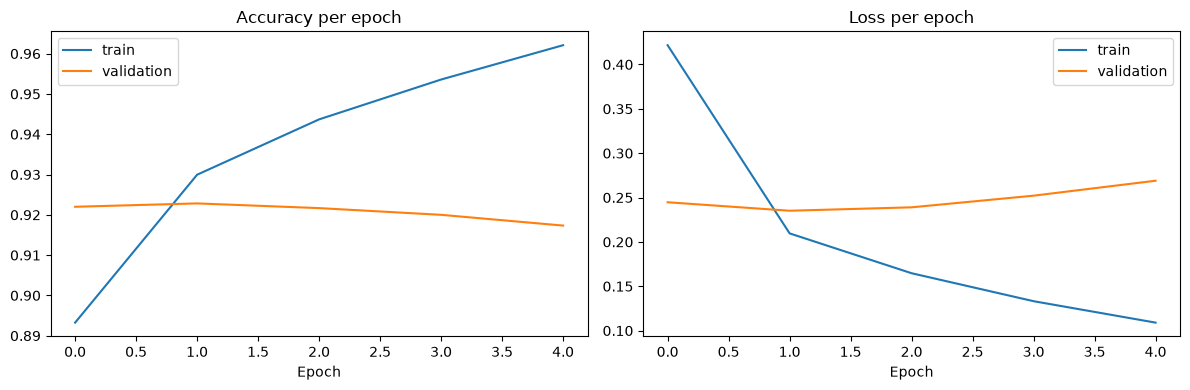

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy per epoch"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss per epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig("nn_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 8: Compare all models

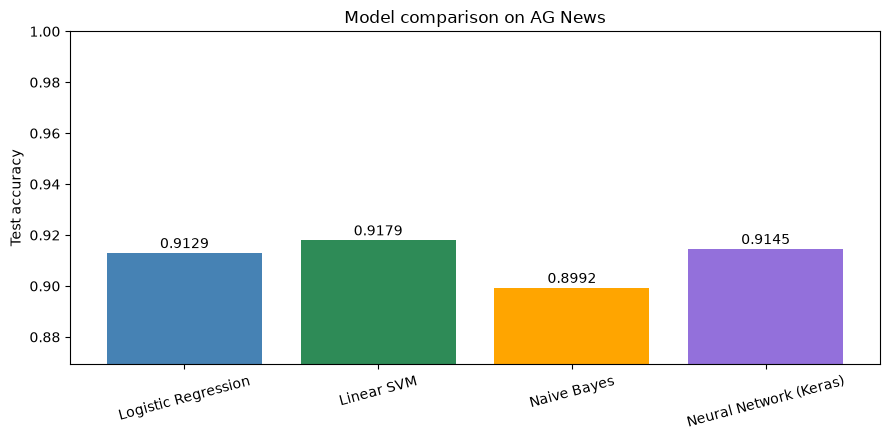

Results:
  Linear SVM               0.9179
  Neural Network (Keras)   0.9145
  Logistic Regression      0.9129
  Naive Bayes              0.8992

Best model: Linear SVM


In [18]:
results["Neural Network (Keras)"] = nn_acc

names = list(results.keys())
accs = list(results.values())

plt.figure(figsize=(9, 4.5))
bars = plt.bar(names, accs, color=["steelblue", "seagreen", "orange", "mediumpurple"])
plt.ylim(min(accs) - 0.03, 1)
plt.ylabel("Test accuracy")
plt.title("Model comparison on AG News")
plt.xticks(rotation=15)
for b, a in zip(bars, accs):
    plt.text(b.get_x() + b.get_width() / 2, a + 0.002, f"{a:.4f}", ha="center")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

best = max(results, key=results.get)
print("Results:")
for n, a in sorted(results.items(), key=lambda x: -x[1]):
    print(f"  {n:<24} {a:.4f}")
print(f"\nBest model: {best}")